In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation')
pth_cb = os.path.join(pth_out, 'colorbars')

In [3]:
# select genes: Gast | pSom (XOR)
get_feat = lambda pth: set(pd.read_csv(pth).mmusculus)
g1 = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
g2 = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = list(g1 ^ g2)

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata = adata[:, g].copy(); adata

AnnData object with n_obs × n_vars = 11243 × 123
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
# module mutual correlations (co-repression | cooperation)
for src, sdf in adata.obs.groupby('source', observed = True):
    adata_src = adata[sdf.index].copy()
    n_bins = (sdf.shape[0] // 800)
    print(src, n_bins)

    # compute neighbors & pseudotime windows
    sc.pp.neighbors(adata_src, 100, use_rep = 'X_mesencoder')
    adata_src.obs['t_bin'] = pd.cut(sdf.t, bins = n_bins)

    # windowed correlations
    r_dict = dict()
    for bin, sdf_bin in adata_src.obs.groupby('t_bin', observed = True):
        adata_bin = adata_src[sdf_bin.index].copy()
        X = pd.DataFrame(adata_bin.X.toarray(),
                         index = sdf_bin.index,
                         columns = adata.var_names)
        X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
        mod1 = sdf_bin.GSE162534.values[:, None]
        mod2 = sdf_bin.GSE229103.values[:, None]
        a = pearsonr(X, mod1, axis = 0).statistic
        b = pearsonr(X, mod2, axis = 0).statistic
        r_dict[bin] = np.corrcoef(a, b)[0, 1]

    # smoothing (neighbors)
    A = adata_src.obsp['connectivities']
    R = adata_src.obs.t_bin.map(r_dict).astype(float)
    R_sm = (A @ R) / A.sum(axis = 1).A1
    adata.obs.loc[sdf.index, 'correlation'] = R_sm

GSE162534 8
GSE229103 5


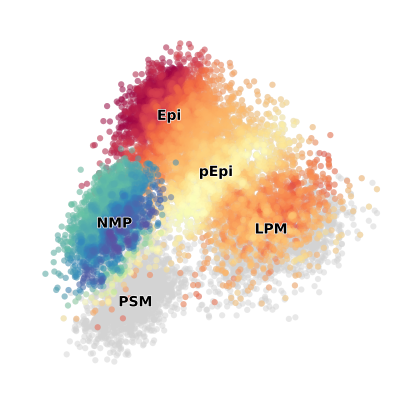

In [6]:
q_plt = (('GSE162534', .75), ('GSE229103', .5))
grp = adata.obs.groupby('source', observed = True)
get_thresh = lambda src, q: grp.get_group(src).t.quantile(q)
thresh_dict = {src : get_thresh(src, q) for src, q in q_plt}
thresh = adata.obs.source.map(thresh_dict).astype(np.float32)
adata_plt = adata[adata.obs.t < thresh].copy()

pad = .05
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
sc.pl.embedding(adata_plt, 'X_mesencoder', dimensions = [1, 0],
                color = 'correlation', cmap = 'Spectral',
                vcenter = 0, size = 80, alpha = .5,
                colorbar_loc = None, frameon = False,
                show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = 0,
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

xlim = ax.get_xlim(); ylim = ax.get_ylim()
xlim = (xlim[0], xlim[1] - .375)
xpad = pad * (xlim[1] - xlim[0])
ypad = pad * (ylim[1] - ylim[0])
ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)

label_dict = {
    'Epiblast'                   : 'Epi',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Neuromesodermal Progenitor' : 'NMP',
    'Posterior Epiblast'         : 'pEpi',
    'Presomitic Mesoderm'        : 'PSM'}

for label in ax.texts:
    _label_ = label.get_text()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])

fn = os.path.join(pth_out, 'correlation.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_2162068/1101920367.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


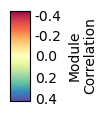

In [7]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Module\nCorrelation')
cb.ax.invert_yaxis()
ticks = np.asarray([-.4, -.2, 0, .2, .4])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'R_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')